# Titanic: exploration with pandas and visualisation with seaborn

![image.png](attachment:image.png)

![image.png](attachment:image.png)

# Analyse de données

# Le Titanic

Comme vous le savez certainement, le RMS Titanic a coulé lors de son
voyage inaugural dans la nuit du 14 au 15 avril 1912 (plus
d’informations voir la page wikipedia de la catastrophe )

Ce qui est intéressant, c'est que l'on a récupéré le manifeste du navire
qui contient de nombreuses informations. Certains s'amusent à prédire
les personnes qui vont survivre à partir des informations de ce
manifeste et y arrivent relativement bien. La prédiction de la survie
des passagers est un exercice de Data Science intéressant mais il
dépasse le niveau de ce cours. Je vous propose ici à partir des éléments
que nous avons vus de tirer et visualiser des informations.

## Chargement des données et exploration

Les données sont stockées au format csv dans un fichier
'data-titanic.csv' qui vous sera fourni par votre enseignant. Utilisez
pandas vous lire ces données et affichez par exemples les 10 premières
lignes.

Le fichier comporte 1309 lignes. La page wikipedia nous indique 953
passagers et 899 membres d'équipage ce qui semble indiqué que notre base
est incomplète, ce qui est généralement souvent le cas.

Voici quelques informations sur les colonnes de notre manifeste du RMS
Titanic :

-   PassengerId : numéro unique de passage

-   Survived : 1,0 si le passager a survécu 0 sinon

-   Pclass : classe du passager

-   Name : nom du passager

-   Sex : sexe du passager

-   Age : âge du passager

-   SibSp : nombre de parents/épouses présents sur le HMS Titanic

-   Parch : nombre de parents / enfants

-   Ticket : numéro du ticket

-   Fare : montant du billet

-   Cabin : catégorie de la cabine

-   Embarked : port d'embarquement (C= Cherbourg, Q=Queentown, S =
    Southampton)

In [2]:
import pandas as pd
titanic = pd.read_csv('data-titanic.csv')
titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,NaN,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
1305,1306,NaN,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
1306,1307,NaN,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
1307,1308,NaN,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


### Quels sont les données entier, réel, objets ?

### Donnez une description des données concernant le Titanic

### Calculez le nombre de personnes qui ont survécu, calculez le pourcentage

J'ai trouvé sur 891 données renseignées, 549 décès et 342 survivants.

décès 61,61 %

survivants ; 38,38 %

In [31]:
surv=titanic["Survived"]
print("total",surv.count())
print("decès ",surv.value_counts()[0])
print("survivants",surv.value_counts()[1])

total 891
decès  549
survivants 342


In [33]:
surv.value_counts() / surv.count() *100

0.0    61.616162
1.0    38.383838
Name: Survived, dtype: float64

### La méthode groupby

Il est temps d'introduire une nouvelle méthode qui nous permet de
travailler sur les DataFrame de manière agréable. Il s'agit de la
méthode groupy() qui permet de grouper les données suivant certains
critères.

Généralement, on part du principe que groupby() est basé sur trois
étapes : séparation, application et combinaison.

La **séparation** est la partie la plus simple, on sépare notre
DataFrame en fonction d'un critère (généralement une ou plusieurs
colonnes). Ensuite, on **applique** des fonctions sir les groupes
obtenus à l'étape précédente. Finalement, on **combine** les résultats
obtenus pour chaque groupe.

La feuille de (*Python pour le Data Scientist*– E. Jakobowicz), vous
donne quelques-une des fonctions qu'il est possible d'appeler après
avoir réalisé la séparation.

par exemple pour grouper les éléments de la DataFrame suivant la classe
des cabines, on pourra écrire :

![image.png](attachment:image.png)

In [36]:
test = titanic.groupby('Pclass')
test.sample(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1157,1158,NaN,1,"Chisholm, Mr. Roderick Robert Crispin",male,NaN,0,0,112051,0.0000,NaN,S
889,890,1.0,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C
581,582,1.0,1,"Thayer, Mrs. John Borland (Marian Longstreth M...",female,39.0,1,1,17421,110.8833,C68,C
1104,1105,NaN,2,"Howard, Mrs. Benjamin (Ellen Truelove Arman)",female,60.0,1,0,24065,26.0000,NaN,S
980,981,NaN,2,"Wells, Master. Ralph Lester",male,2.0,1,1,29103,23.0000,NaN,S
1170,1171,NaN,2,"Oxenham, Mr. Percy Thomas",male,22.0,0,0,W./C. 14260,10.5000,NaN,S
1159,1160,NaN,3,"Howard, Miss. May Elizabeth",female,NaN,0,0,A. 2. 39186,8.0500,NaN,S
929,930,NaN,3,"Sap, Mr. Julius",male,25.0,0,0,345768,9.5000,NaN,S
1021,1022,NaN,3,"Spinner, Mr. Henry John",male,32.0,0,0,STON/OQ. 369943,8.0500,NaN,S


### Calculer pour chaque classe de cabines, le pourcentage de passager survivants

Voici les valeurs que j'ai trouvées :

Nombre de passagers survivants :

-   1ère classe : 136 \~ 62,96%
-   2ème classe : 87 \~ 47%
-   3ème classe : 119 \~ 24%

In [93]:
k=titanic['Pclass'].value_counts()

In [94]:
a=titanic[['Pclass','Survived']].groupby('Pclass')
b=a.mean()*100
b

,Survived
Pclass,
1,62.962963
2,47.282609
3,24.236253


In [105]:
titanic[titanic['Survived'] == 1.0].groupby('Pclass').count()

,PassengerId,Survived,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Pclass,,,,,,,,,,,
1,136,136,136,136,122,136,136,136,136,117,134
2,87,87,87,87,83,87,87,87,87,13,87
3,119,119,119,119,85,119,119,119,119,6,119


### Calculez le pourcentage d'hommes et de femmes survivantes

J'ai trouvé qu'il y avait 314 femmes et que le le pourcentage de survie
était de 74,2 %

In [114]:
titanic[['Sex','Survived']].groupby('Sex').mean()*100

,Survived
Sex,
female,74.203822
male,18.890815


In [132]:
f=titanic.groupby('Sex').count()
f


,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Sex,,,,,,,,,,,
female,466,314,466,466,388,466,466,466,466,141,464
male,843,577,843,843,658,843,843,843,842,154,843


In [136]:
f.loc['female']['Survived']

314

### Calculez le nombre est le pourcentage de survivants suivant le lieu d’embarquement

Rappelez-vous que le C signifie Cherbourg ; Q Queentown et S
Southhampton

J'ai trouvé que 55 % des personnes embarquées à Cherbourg avaient
survécu, 38 % à Queenstown et 33 % à Southampton.

Allez plus loin dans l'analyse de ces valeurs et donnez pour cahque port
d'embarquement le pourcentage d'hommes et de femmes qui ont survécu.

In [137]:
titanic[['Embarked','Survived']].groupby('Embarked').mean()*100

,Survived
Embarked,
C,55.357143
Q,38.961039
S,33.695652


In [149]:
titanic.groupby(['Sex','Embarked']).count()

PassengerId  Survived  Pclass  Name  Age  SibSp  Parch  \
Sex    Embarked                                                           
female C                 113        73     113   113   98    113    113   
       Q                  60        36      60    60   24     60     60   
       S                 291       203     291   291  264    291    291   
male   C                 157        95     157   157  114    157    157   
       Q                  63        41      63    63   26     63     63   
       S                 623       441     623   623  518    623    623   

                 Ticket  Fare  Cabin  
Sex    Embarked                       
female C            113   113     59  
       Q             60    60      3  
       S            291   291     77  
male   C            157   157     59  
       Q             63    63      2  
       S            623   622     93

In [154]:
titanic[['Embarked','Survived','Sex']].groupby(['Embarked','Sex']).mean()*100

Survived
Embarked Sex              
C        female  87.671233
         male    30.526316
Q        female  75.000000
         male     7.317073
S        female  68.965517
         male    17.460317

### Quel est l'âge du capitaine ?

### Quel est l'âge moyen des passagers ?

Et l'âge moyen des personnes ayant survécu, décédé ?

29,8 ans

28,34 ans pour les survivants

30,62 ans pour ceux n'ayant pas survécu

Quel est l'âge du plus jeune et du passager le plus âgé ? Quel est son
nom ?

0,17 ans Dean, Miss. Elizabeth Gladys Millvina

et 80 ans

In [158]:
titanic['Age'].mean()

29.881137667304014

In [177]:
titanic[['Survived','Age']].groupby(['Survived']).mean()

,Age
Survived,
0.0,30.626179
1.0,28.343690


In [179]:
titanic['Age'].min()

0.17

In [182]:
titanic[titanic['Age']==0.17]['Name']

1245    Dean, Miss. Elizabeth Gladys Millvina""
Name: Name, dtype: object

In [180]:
titanic['Age'].max()

80.0

In [192]:
titanic[titanic['Age']==80]['Name'].iloc[0]

'Barkworth, Mr. Algernon Henry Wilson'

## Données incohérentes et manquantes

La méthode isnull appliqué sur un DataFrame permet de retourner un
tableau de booléens indiquant l'absence de données (True) ou la présence
de données (False).

En écrivant un petit script python, retournez le nombre de valeurs
manquantes de chaque colonne. Voici les valeurs que j'ai trouvées :

\[0, 418, 0, 0, 0, 263, 0, 0, 0, 1, 1014, 2\]

Il y a beaucoup de valeurs manquantes pour l'avant-dernière colonne (le
numéro de la cabine, mais a priori ce n'est pas très important)

Il existe un package missingno qui permet de visualiser les valeurs
manquantes dans une Series et une DataFrame. Essayez de l'importez avec
votre programme d'installation préféré :

In [237]:
count=0
rows=titanic.count().iloc[0]
isnl=titanic.isnull()
l=[]
for i in range(len(titanic.columns)):
  for j in range(rows):
    if ((isnl.iloc[j][i])==True):
      count+=1
  l.append(count)
  count=0
print(l)


[0, 418, 0, 0, 0, 263, 0, 0, 0, 1, 1014, 2]


In [ ]:
pip install missingno

In [ ]:
import missingno as msno

Avec la commande matrix de ce module, visualisez les sonnées manquantes.
Est-ce cohérent avec le calcul effectué précédemment ? Qu'en
déduisez-vous ?

![image.png](attachment:image.png)

De même, utilisez la commande heatmap de ce module sur nos données.
Qu'est-ce que cela représente à votre avis ?

## Correction de la base de données

Il y a certains éléments de notre base que nous ne savons pas corriger
et qu'il est inutile de corriger (typiquement la colonne Survived) mais
nous pouvons par exemple modifier certains données pour avoir un
DataFrame plus « cohérent ».

-   Déjà nous allons commencer par enlever les colonnes qui nous gênent
    et n'apportent pas d'informations mais bien sûr, on peut se tromper.
    Avec la commande drop, enlevez les colonnes Ticket et Cabin
-   Je vous propose de remplacer les âges manquants par l'âge moyen ou
    médian de chaque classe

## Part 2: visualisation with seaborn

# RETOUR SUR LE TITANIC
## Visualisation des données

In [1]:
import pandas as pd

In [2]:
import seaborn as sns

In [3]:
import matplotlib.pyplot as plt

In [4]:
titanic = pd.read_csv('./data-titanic.csv')

In [5]:
titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,NaN,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
1305,1306,NaN,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
1306,1307,NaN,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
1307,1308,NaN,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


Nous allons utiliser une particularité intéressante des barcode de seaborn [Barplot](https://seaborn.pydata.org/generated/seaborn.barplot.html?highlight=barplot#seaborn.barplot), ils calculent automatiquement la moyenne d'une Series

#### des graphismes _simples_

Affichez un avec graphisme catégoriel le nombre d'hommes et de femmes à bord du Titanic

### countplot

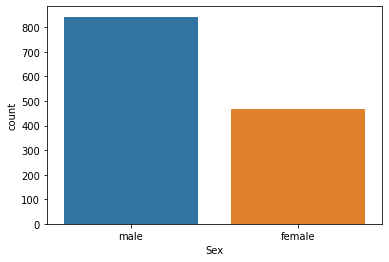

In [13]:
sns.countplot(data=titanic, x = 'Sex')

Faîtes de même pour :
* afficher le nombre de personnes par classe
* afficher le nombres de personnes pour chaque port d'embarquement

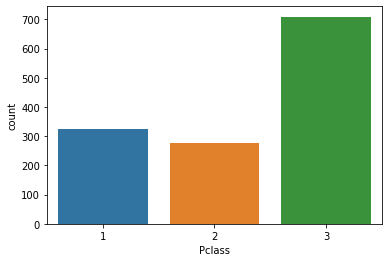

In [22]:
sns.countplot(data=titanic, x = 'Pclass')

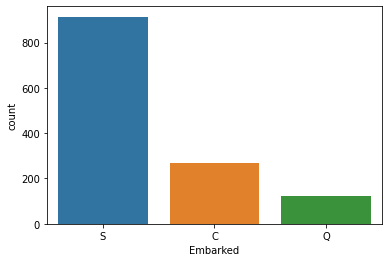

In [21]:
sns.countplot(data=titanic, x = 'Embarked')

### boxplot

En utilisant la commande **boxplot**, afficher :
* l'âge des passagers du Titanic
* le prix payé pour les tickets

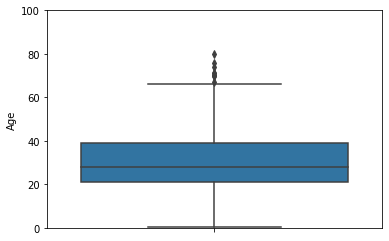

In [17]:
plt.ylim(0,100)
# à vous
sns.boxplot(data = titanic, y = 'Age')


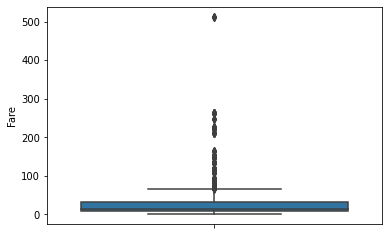

In [23]:
sns.boxplot(data = titanic, y = 'Fare')

En Utilisant la commande **hue** pour une visualisation suivant une 3ème dimension, visualiser les âges des passagers en fonction du port d'embarquement et suivant le sexe des passagers

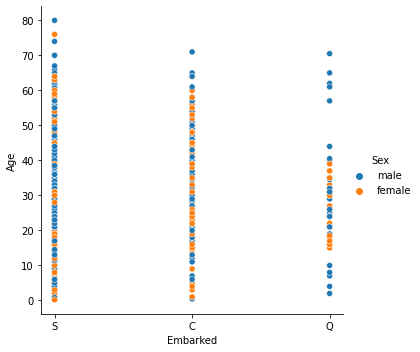

In [29]:
# à vous
sns.relplot(data = titanic,
               x = 'Embarked',
               y = 'Age',
               hue = 'Sex',
               kind = 'scatter')

La commande **violinplot** est une commande très proche de boxplot qui permet

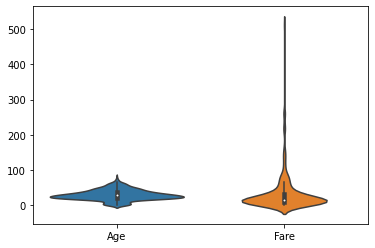

In [27]:
sns.violinplot(data=titanic[['Age','Fare']])

Que fait la commande suivante ?
Qu'en déduisez-vous ?

<AxesSubplot:ylabel='Fare'>

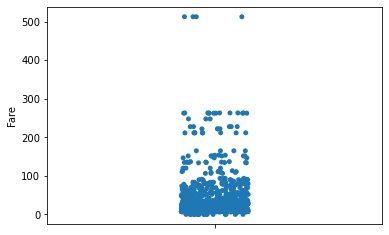

In [ ]:
sns.stripplot(data = titanic, y = 'Fare')

### swarmplot

Utilisez la commande **swarmplot** au lieu de boxplot (c'est une commande similaire)
Qu'en déduisez-vous ?

De même, utilisez cette commande afin d'afficher les âges de tous les passagers en fonction de leur classe

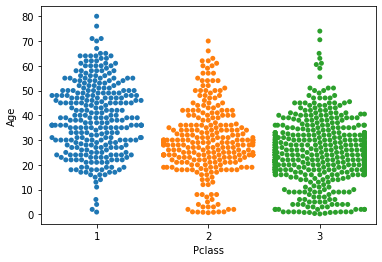

In [31]:
# à vous
sns.swarmplot(data = titanic, x = 'Pclass', y = 'Age')

Utilisez l'option *hue* afin de visualiser les passagers par classe, par âge et suivant ou non s'ils ont survécu

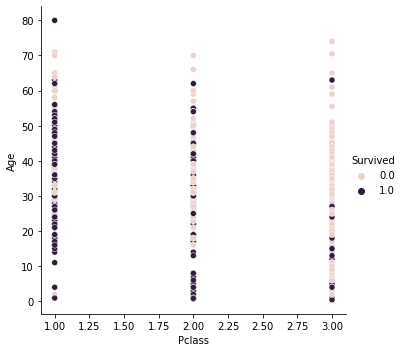

In [35]:
# à vous
sns.relplot(data = titanic,
               x = 'Pclass',
               y = 'Age',
               hue = 'Survived',
               kind = 'scatter')

Représentez l'âge des passagers en fonction du lieu d'embarquement et suivant s'ils ont ou non survécu

<Figure size 1080x360 with 0 Axes>

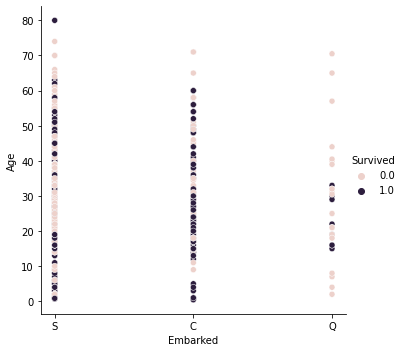

In [36]:
plt.figure(figsize=(15,5))
sns.relplot(data = titanic,
               x = 'Embarked',
               y = 'Age',
               hue = 'Survived',
               kind = 'scatter')

Représentez le prix payé par les passagers en fonction de la classe et suivant s'ils ont survécu ou non

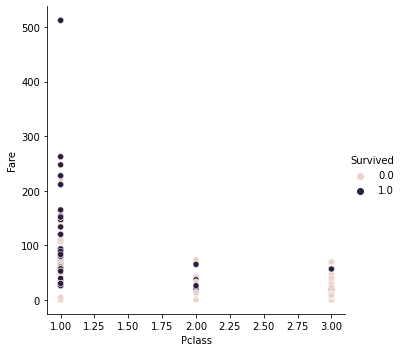

In [38]:
#plt.figure(figsize=(15,5))
#plt.ylim(0,300)
sns.relplot(data = titanic,
               x = 'Pclass',
               y = 'Fare',
               hue = 'Survived',
               kind = 'scatter')

In [64]:
test = titanic[['Sex','Survived']].groupby('Sex').mean()
test

,Survived
Sex,
female,0.742038
male,0.188908


### barplot

Affichez le pourcentage de survivants suivant le sex

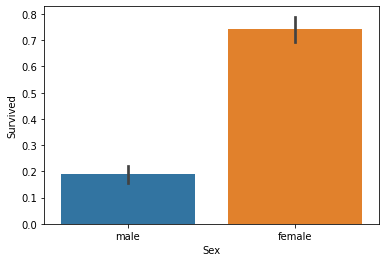

In [68]:
sns.barplot(data = titanic , x = 'Sex',y='Survived')

Affichez le pourcentage de survivants par classe

In [ ]:
test2 = titanic[['Survived','Pclass']].groupby('Pclass').mean()
test2

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


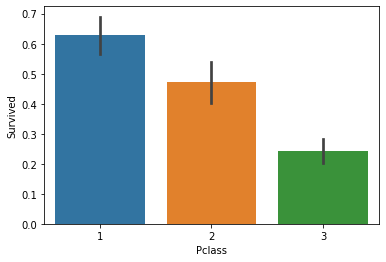

In [69]:
# à vous
sns.barplot(data = titanic , x = 'Pclass',y='Survived')

Afficher avec un countplot le nombre de survivants par classe et pas sexe

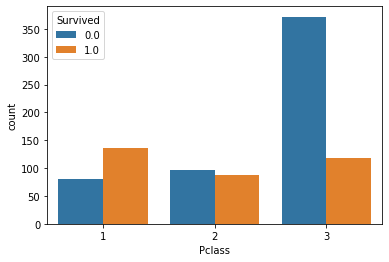

In [82]:
#  à vous
sns.countplot(data = titanic, hue = 'Survived', x = 'Pclass')

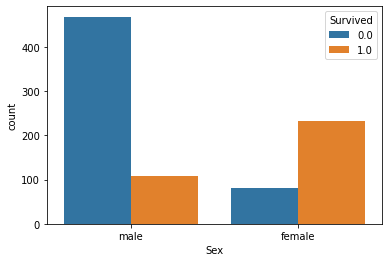

In [83]:
sns.countplot(data = titanic, hue = 'Survived', x = 'Sex')

In [ ]:
test3 = titanic[['Pclass','Sex','Survived']].groupby(['Pclass','Sex']).mean()
test3

Survived
Pclass Sex             
1      female  0.968085
       male    0.368852
2      female  0.921053
       male    0.157407
3      female  0.500000
       male    0.135447

Utilisez **barplot** qui vous permet de calculer automatiquement la moyenne

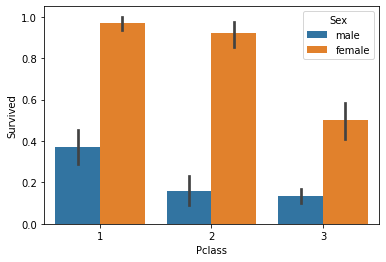

In [84]:
# à vous
sns.barplot(data = titanic , x = 'Pclass',y='Survived',hue='Sex')

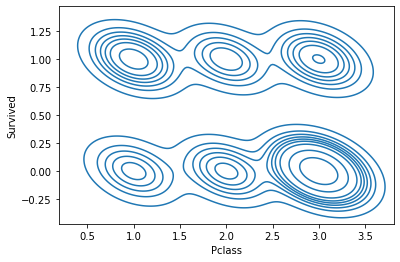

In [85]:
sns.kdeplot(data = titanic, x = 'Pclass', y = 'Survived')

Qu'est-ce que cette visualisation (au-dessus) ?

Embarquement et survie

In [ ]:
test4 = titanic[['Embarked','Survived']].groupby(['Embarked']).mean()
test4

,Survived
Embarked,
C,0.553571
Q,0.389610
S,0.336957


Retrouver les valeurs ci-dessus avec un barplot

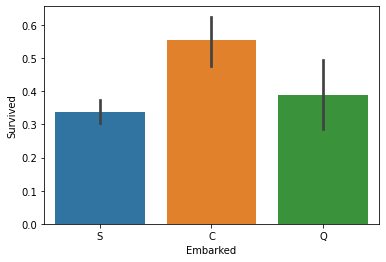

In [86]:
# à vous
sns.barplot(data = titanic , x = 'Embarked',y='Survived')

Affichez le nombre de personnes dans chaque port et distinguez chaque sexe

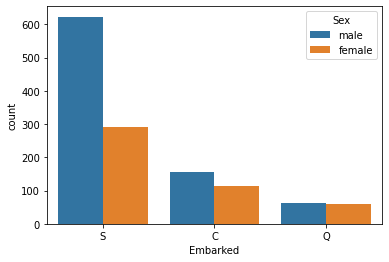

In [139]:
sns.countplot(data = titanic, x = 'Embarked', hue = 'Sex')

In [125]:
corr = titanic[['Age','Sex','Pclass','Fare','Embarked']].groupby('Embarked').mean()
corr

,Age,Pclass,Fare
Embarked,,,
C,32.332170,1.851852,62.336267
Q,28.630000,2.894309,12.409012
S,29.245205,2.347921,27.418824


In [ ]:
Est-ce que le prix est une variable catégorielle ou numérique

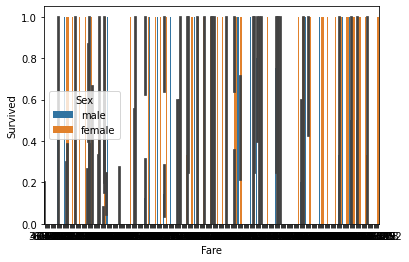

In [126]:
sns.barplot(data = titanic, x = 'Fare', y = 'Survived', hue = 'Sex')

Il y a trop de données sur la **tarification**, c'est une variable numérique

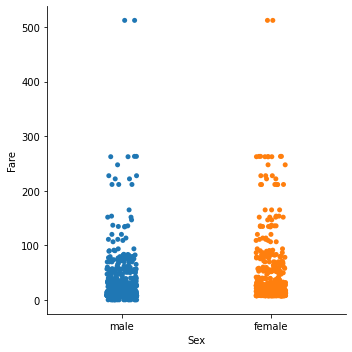

In [127]:
sns.catplot(data = titanic, x = 'Sex', y = 'Fare')

Pas facile, facile d'en déduire quelque chose essayez **boxplot**

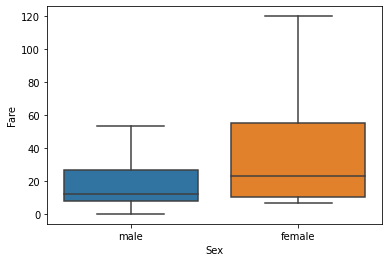

In [131]:
sns.boxplot(data = titanic,x='Sex' ,y='Fare',showfliers=False)

C'est déjà beaucoup mieux, utilisez **swarmplot**

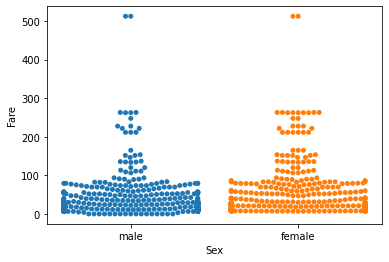

In [136]:
sns.swarmplot(data=titanic,x='Sex',y='Fare')

C'est déjà beaucoup mieux, utilisez **swarmplot** et distinguez les personnes qui ont survécu des personnes décédées

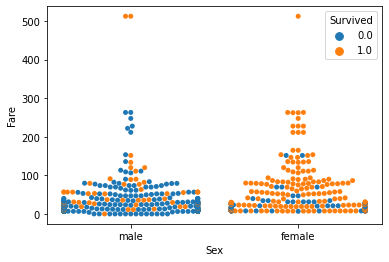

In [138]:
sns.swarmplot(data=titanic,x='Sex',y='Fare',hue='Survived')

Comme on l'a vu dans le cours quand on souhaite trouver une corrélation entre deux varaibles numériques, scatterplot est une très bonne méthode. Faîtes-le entre l'âge et le prix du ticket

In [ ]:
# à vous

Malheureusement, on ne peut en déduire beaucoup d'informations car le prix du voyage n'est pas assez dispersé (ce n'est pas une véritable, c'est une fausse variable catégorielle

Pour cela, je vous propose de la transformer en une variable catégorielle.

Pour réaliser cette transformation :
1. calculer la moyenne ou la médiane de chaque classe
2. en utilisant un script python, affecter à chaque passager, le prix qui correspond à sa classe
3. afficher en utilisant un catplot le prix en fonction de l'âge et si le passager a survécu ou non

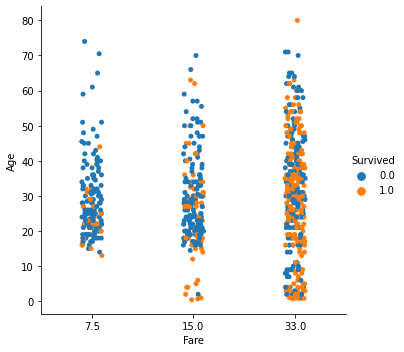

In [ ]:
# à vous

Afin de définir une heatmap, on ne va conserver que les données
du __Titanic__ qui nous intéressent

In [ ]:
heat = titanic[['Age','Pclass','Fare','Embarked','Sex','Survived']]
heat

,Age,Pclass,Fare,Embarked,Sex,Survived
0,22.0,3,7.2500,S,male,0.0
1,38.0,1,71.2833,C,female,1.0
2,26.0,3,7.9250,S,female,1.0
3,35.0,1,53.1000,S,female,1.0
4,35.0,3,8.0500,S,male,0.0
...,...,...,...,...,...,...
1304,NaN,3,8.0500,S,male,NaN
1305,39.0,1,108.9000,C,female,NaN
1306,38.5,3,7.2500,S,male,NaN
1307,NaN,3,8.0500,S,male,NaN


On supprime les lignes où :
1. on ne connait pas si la personne a survécu ou non
2. il faut des chiffres donc pour le sexe Mâle 0, Femelle 1
3. port d'embarquement S 0 C 1 Q 2
4. on calcule les corrélations colonnes par colonnes avec la commande corr()

In [ ]:
heat = heat[heat['Survived'].notnull()]

In [ ]:
heat['Sex'].replace(['male','female'],[0,1],inplace=True)
heat['Embarked'].replace(['S','C','Q'],[0,1,2],inplace=True)
heat

,Age,Pclass,Fare,Embarked,Sex,Survived
0,22.0,3,7.2500,0.0,0,0.0
1,38.0,1,71.2833,1.0,1,1.0
2,26.0,3,7.9250,0.0,1,1.0
3,35.0,1,53.1000,0.0,1,1.0
4,35.0,3,8.0500,0.0,0,0.0
...,...,...,...,...,...,...
886,27.0,2,13.0000,0.0,0,0.0
887,19.0,1,30.0000,0.0,1,1.0
888,NaN,3,23.4500,0.0,1,0.0
889,26.0,1,30.0000,1.0,0,1.0


In [128]:
plt.figure(figsize=(15,10))
sns.heatmap(heat.corr())

<Figure size 1080x720 with 0 Axes>

Qu'est-ce que c'est ?